# 18. A project: from exchanger data to a cleaning schedule

**Track:** project &nbsp;·&nbsp; **Prerequisites:** Chapters 11 and 17

Every heat exchanger in a refinery slowly fouls. Deposits from the oil build up on the
tubes, add a thermal resistance, and the exchanger recovers less heat; the furnace
downstream burns more fuel to make up the difference. Cleaning restores the exchanger, but
it costs money and takes it out of service. When should it be cleaned? The answer needs
three things the earlier chapters provide: the effectiveness of an exchanger (Chapter 11),
a model of how the fouling grows, and an honest account of how well the plant's own
measurements determine that model.

This closing chapter is a project in that sense. It starts where an engineer starts, from a
year of daily readings of flows and temperatures, and ends with a cleaning interval and its
uncertainty. The readings here are *synthetic*: they are generated from a known fouling law,
with day-to-day changes in operation and realistic measurement noise, so that every step can
be checked against the truth. The method is the one to apply to real plant data, where the
truth is not known.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import exchangers
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import exchangers
from engtransport.plotting import panel_label, use_style

use_style()
ex = exchangers
FLOW = "shell_and_tube_1_2n"

## 18.1 The exchanger and the synthetic plant record

The exchanger preheats crude oil with a hot residue stream in a refinery; it is a 1-2
shell-and-tube unit with 250 m² of surface and a clean overall coefficient of
350 W/(m² K). Nominally 30 kg/s of residue ($c_p = 2500$ J/(kg K)) enters at 300 °C and
40 kg/s of crude ($c_p = 2100$ J/(kg K)) at 130 °C. These are assumed values of a typical
size. The synthetic record has one reading a day for a year after a cleaning. Each day the
flows vary by 5 % and the inlet temperatures by 5 K and 3 K (standard deviations), as
operation does; the instruments then add noise of 1 % to each flow and 0.3 K to each
temperature. The deposit grows by the law of Kern and Seaton (1959),

$$
\frac{dR_f}{dt} = \phi_d - \frac{R_f}{\tau}
\quad\Longrightarrow\quad
R_f = R_\infty\left(1 - e^{-t/\tau}\right) ,
\tag{18.1}
$$

in which deposition at a constant rate $\phi_d$ is balanced by removal (shear stripping
the deposit) in proportion to its amount, so that the resistance levels off at
$R_\infty = \phi_d\tau$. The synthetic truth is $R_\infty = 1.2\times10^{-3}$ m² K/W and
$\tau = 80$ days: the asymptotic resistance cuts the overall coefficient by 30 %.

In [2]:
A, U_clean = 250.0, 350.0
cp_h, cp_c = 2500.0, 2100.0
m_h0, m_c0, T_hi0, T_ci0 = 30.0, 40.0, 573.15, 403.15
R_TRUE, TAU_TRUE = 1.2e-3, 80.0                 # synthetic truth
SIG_T, SIG_M = 0.3, 0.01                         # instrument noise (synthetic)
days = np.arange(0.0, 366.0)


def eff12(NTU, Cr):
    """1-2 shell-and-tube effectiveness, Eq. (11.8), vectorised."""
    s = np.sqrt(1.0 + Cr**2)
    e = np.exp(-NTU * s)
    return 2.0 / (1.0 + Cr + s * (1.0 + e) / (1.0 - e))


def plant_record(rng, R_inf=R_TRUE, tau=TAU_TRUE, n_days=366):
    """One synthetic year: true operation from Eq. (18.1), then noisy readings."""
    t = np.arange(float(n_days))
    m_h = m_h0 * (1 + 0.05 * rng.standard_normal(n_days))
    m_c = m_c0 * (1 + 0.05 * rng.standard_normal(n_days))
    T_hi = T_hi0 + 5.0 * rng.standard_normal(n_days)
    T_ci = T_ci0 + 3.0 * rng.standard_normal(n_days)
    R_f = ex.asymptotic_fouling(t, R_inf, tau)
    C_h, C_c = m_h * cp_h, m_c * cp_c
    C_min = np.minimum(C_h, C_c)
    Q = eff12(A / (1 / U_clean + R_f) / C_min, C_min / np.maximum(C_h, C_c)) * C_min * (T_hi - T_ci)
    true = {"t": t, "R_f": R_f, "Q": Q, "m_h": m_h, "m_c": m_c, "T_hi": T_hi, "T_ci": T_ci,
            "T_ho": T_hi - Q / C_h, "T_co": T_ci + Q / C_c}
    noisy = {k: true[k] * (1 + SIG_M * rng.standard_normal(n_days)) for k in ("m_h", "m_c")}
    noisy |= {k: true[k] + SIG_T * rng.standard_normal(n_days) for k in ("T_hi", "T_ho", "T_ci", "T_co")}
    return true, noisy


def fouling_from_readings(r):
    """Eqs. (18.2)-(18.4): duty, effectiveness, NTU, UA and the fouling resistance."""
    out = ex.ua_from_temperatures(r["m_h"], cp_h, r["T_hi"], r["T_ho"], r["m_c"], cp_c, r["T_ci"], r["T_co"], FLOW)
    out["R_f"] = A / out["UA"] - 1 / U_clean
    return out


rng = np.random.default_rng(2026)
true, meas = plant_record(rng)
est = fouling_from_readings(meas)
print(f"clean: duty {true['Q'][0] / 1e6:.2f} MW, effectiveness {est['eps'][0]:.3f}, NTU {est['NTU'][0]:.2f};"
      f" after a year: {true['Q'][-1] / 1e6:.2f} MW, U {1 / (1 / U_clean + true['R_f'][-1]):.0f} W/(m2 K)")
print(f"heat-balance imbalance of the readings: {100 * np.std(est['imbalance']):.1f} % (standard deviation)")
print(f"scatter of the daily R_f about the truth: {np.std(est['R_f'] - true['R_f']):.2e} m2K/W"
      f" ({100 * np.std(est['R_f'] - true['R_f']) / R_TRUE:.1f} % of R_inf)")

clean: duty 6.23 MW, effectiveness 0.515, NTU 1.22; after a year: 5.40 MW, U 247 W/(m2 K)
heat-balance imbalance of the readings: 1.6 % (standard deviation)
scatter of the daily R_f about the truth: 3.51e-05 m2K/W (2.9 % of R_inf)


## 18.2 From readings to fouling resistance

Each day's readings give the duty from both streams; their mean is the best estimate, and
their difference, the heat-balance imbalance, is a first test of the instruments:

$$
Q = \tfrac12\left[C_h\left(T_{hi} - T_{ho}\right) + C_c\left(T_{co} - T_{ci}\right)\right] ,
\qquad C = \dot m c_p .
\tag{18.2}
$$

The effectiveness follows as $\varepsilon = Q/[C_{min}(T_{hi} - T_{ci})]$, and the inverse
of the effectiveness relation of Chapter 11 gives the NTU and hence $UA$ (for the 1-2
exchanger the inverse is in closed form):

$$
\varepsilon = \frac{Q}{C_{min}\left(T_{hi} - T_{ci}\right)} ,
\qquad
UA = C_{min}\,NTU(\varepsilon, C_r) .
\tag{18.3}
$$

The fouling resistance is what has been added to the clean resistance:

$$
R_f = \frac{A}{UA} - \frac{1}{U_{clean}} .
\tag{18.4}
$$

The clean coefficient must itself be known, from the first days after a cleaning or from
the design. Using UA rather than the duty matters: the duty changes from day to day with
the flows and inlet temperatures, by more than the fouling changes it, but UA (and so $R_f$)
does not. The noise of the instruments passes into $R_f$ through Eqs. (18.2)–(18.4). To
first order, with $x_i$ the eight readings and $\sigma_i$ their noise,

$$
\sigma_{R}^2 = \sum_i \left(\frac{\partial R_f}{\partial x_i}\right)^2 \sigma_i^2 ,
\tag{18.5}
$$

the propagation of errors. Here it gives a daily scatter of $2.9\times10^{-5}$ m² K/W for
the clean exchanger and $3.9\times10^{-5}$ when fouled, 2 to 3 % of $R_\infty$; the
crude flow and the two outlet temperatures contribute most. Each day alone says little,
but a year of days says a great deal.

In [3]:
# Eq. (18.5) by finite-difference derivatives at nominal conditions, clean and fouled
def r_f_of(x):
    r = dict(zip(("m_h", "T_hi", "T_ho", "m_c", "T_ci", "T_co"), x))
    o = ex.ua_from_temperatures(r["m_h"], cp_h, r["T_hi"], r["T_ho"], r["m_c"], cp_c, r["T_ci"], r["T_co"], FLOW)
    return A / o["UA"] - 1 / U_clean


def propagated_sigma(R_f):
    C_h, C_c = m_h0 * cp_h, m_c0 * cp_c
    C_min = min(C_h, C_c)
    Q = eff12(A / (1 / U_clean + R_f) / C_min, C_min / max(C_h, C_c)) * C_min * (T_hi0 - T_ci0)
    x = np.array([m_h0, T_hi0, T_hi0 - Q / C_h, m_c0, T_ci0, T_ci0 + Q / C_c])
    sig = np.array([SIG_M * m_h0, SIG_T, SIG_T, SIG_M * m_c0, SIG_T, SIG_T])
    grad = []
    for i in range(6):
        dx = 1e-6 * max(abs(x[i]), 1.0)
        xp, xm = x.copy(), x.copy()
        xp[i] += dx
        xm[i] -= dx
        grad.append((r_f_of(xp) - r_f_of(xm)) / (2 * dx))
    grad = np.array(grad)
    return math.sqrt(np.sum((grad * sig) ** 2)), grad * sig


sig0, parts0 = propagated_sigma(0.0)
sig1, parts1 = propagated_sigma(R_TRUE)
names = ("hot flow", "T_hi", "T_ho", "cold flow", "T_ci", "T_co")
print(f"Eq. (18.5): sigma_R = {sig0:.2e} clean, {sig1:.2e} fouled; largest contributions (clean): "
      + ", ".join(f"{n} {abs(p):.1e}" for n, p in sorted(zip(names, parts0), key=lambda z: -abs(z[1]))[:3]))

Eq. (18.5): sigma_R = 2.93e-05 clean, 3.87e-05 fouled; largest contributions (clean): cold flow 1.6e-05, T_co 1.6e-05, T_ho 1.4e-05


## 18.3 Fitting the fouling law

Fitting Eq. (18.1) to the daily resistances by least squares,

$$
\min_{R_\infty,\,\tau} \sum_k \left[R_{f,k} - R_\infty\left(1 - e^{-t_k/\tau}\right)\right]^2 ,
\tag{18.6}
$$

is easy because, for a given $\tau$, the best $R_\infty$ is a linear fit; the search is then
over $\tau$ alone (`exchangers.fit_asymptotic_fouling`). The covariance of the two
parameters follows from the Jacobian of the model at the optimum and the scatter of the
residuals; its square roots are the standard errors. A schedule must often be set before a
full year of data exists, so the fit is repeated with the first 30, 60, 120 and 365 days.

In [4]:
fit = ex.fit_asymptotic_fouling(days, est["R_f"])
se = np.sqrt(np.diag(fit["cov"]))
print(f"one year: R_inf = {fit['R_inf']:.4e} +- {se[0]:.1e} (truth {R_TRUE:.1e}),"
      f" tau = {fit['tau']:.1f} +- {se[1]:.1f} d (truth {TAU_TRUE:.0f}); residual scatter {fit['s']:.2e}")
spans = (30, 60, 120, 365)
fits_span = {}
for n in spans:
    f = ex.fit_asymptotic_fouling(days[: n + 1], est["R_f"][: n + 1])
    s = np.sqrt(np.diag(f["cov"]))
    fits_span[n] = f
    print(f"first {n:3d} days: R_inf = {1e3 * f['R_inf']:.3f} +- {1e3 * s[0]:.3f} e-3, tau = {f['tau']:6.1f} +- {s[1]:5.1f} d")

one year: R_inf = 1.2061e-03 +- 3.7e-06 (truth 1.2e-03), tau = 81.1 +- 0.9 d (truth 80); residual scatter 3.51e-05
first  30 days: R_inf = 3.418 +- 6.794 e-3, tau =  249.2 +- 518.6 d
first  60 days: R_inf = 1.232 +- 0.138 e-3, tau =   82.5 +-  12.1 d
first 120 days: R_inf = 1.217 +- 0.030 e-3, tau =   81.8 +-   3.4 d
first 365 days: R_inf = 1.206 +- 0.004 e-3, tau =   81.1 +-   0.9 d


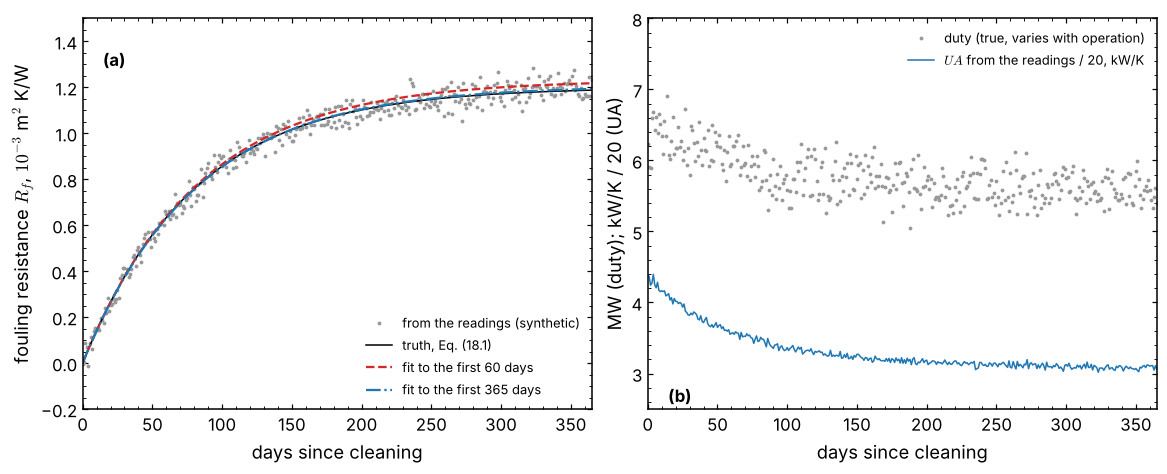

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax1.plot(days, 1e3 * est["R_f"], ".", color="0.6", ms=3, label="from the readings (synthetic)")
ax1.plot(days, 1e3 * true["R_f"], "k-", lw=1.0, label="truth, Eq. (18.1)")
for n, style in ((60, "C3--"), (365, "C0-.")):
    f = fits_span[n]
    ax1.plot(days, 1e3 * ex.asymptotic_fouling(days, f["R_inf"], f["tau"]), style, lw=1.5, label=f"fit to the first {n} days")
ax1.set_xlabel("days since cleaning")
ax1.set_ylabel(r"fouling resistance $R_f$, $10^{-3}$ m$^2$ K/W")
ax1.set_xlim(0, 365)
ax1.set_ylim(-0.2, 1.5)
ax1.legend(loc="lower right", fontsize=8.5)
panel_label(ax1, "(a)", x=0.04, y=0.92)

ax2.plot(days, true["Q"] / 1e6, ".", color="0.6", ms=3, label="duty (true, varies with operation)")
ax2.plot(days, est["UA"] / 1e3 / 20, "C0-", lw=1.0, label=r"$UA$ from the readings / 20, kW/K")
ax2.set_xlabel("days since cleaning")
ax2.set_ylabel("MW (duty); kW/K / 20 (UA)")
ax2.set_xlim(0, 365)
ax2.set_ylim(2.5, 8)
ax2.legend(loc="upper right", fontsize=8.5)
panel_label(ax2, "(b)", x=0.04, y=0.06)
plt.show()

With a year of data the fit gives $R_\infty = 1.206\times10^{-3}$ m² K/W with a standard
error of 0.3 %, and $\tau = 81.1 \pm 0.9$ days, against the true 80. Earlier fits are
much less sure. After 30 days the deposit is still growing almost linearly, the data cannot
tell an asymptote from a straight line, and $\tau$ comes out as $250 \pm 520$ days. After
60 days it is $83 \pm 12$ and after 120 days $82 \pm 3$.

**Figure 18.1.** A synthetic year of a fouling crude preheat exchanger. (a) Fouling
resistance from the daily readings, Eqs. (18.2)–(18.4), the true law, and fits to the first
60 and 365 days. (b) Duty, which scatters with the operation of the day, and the overall
conductance UA, which follows the fouling alone.

## 18.4 When to clean

Let the exchanger be cleaned every $t_c$ days. Between cleanings the lost duty
$Q_0 - Q(t)$ must be made up in the furnace, at a cost $L(t)$ per day; each cleaning costs
$C$ and takes the exchanger out of service for $t_d$ days, during which its whole clean
duty $Q_0$ is lost at a cost $c_dt_d$. The average cost per day over a cycle is

$$
J(t_c) = \frac{C + c_d t_d + \int_0^{t_c} L(t)\,dt}{t_c + t_d} .
\tag{18.7}
$$

Setting $dJ/dt_c = 0$ gives the condition for the best interval:

$$
L(t_c) = J(t_c) ,
\tag{18.8}
$$

clean when the rate at which money is being lost has risen to the average rate over the
cycle. With asymptotic fouling $L(t)$ levels off, and if cleaning is expensive enough the
optimum moves to infinity: never cleaning costs $L(\infty)$ per day, and a finite interval
is worth it only if $J$ dips below that.

The costs assumed are typical: fuel at 6 USD/GJ burnt in a furnace of 85 % efficiency;
15 000 USD per cleaning (bundle pulled and hydro-blasted) and 2 days out of service. The
nominal operation of Section 18.1 sets $Q(t)$ through Eq. (11.8).

In [6]:
FUEL, ETA_F, C_CLEAN, T_DOWN = 6e-9, 0.85, 15000.0, 2.0      # assumed: USD/J, furnace efficiency, USD, days
C_h0, C_c0 = m_h0 * cp_h, m_c0 * cp_c
C_min0, Cr0 = min(C_h0, C_c0), min(C_h0, C_c0) / max(C_h0, C_c0)


def duty(R_f):
    return eff12(A / (1 / U_clean + np.asarray(R_f)) / C_min0, Cr0) * C_min0 * (T_hi0 - T_ci0)


Q0 = float(duty(0.0))
c_W = FUEL / ETA_F * 86400.0                                   # USD per (W day)


def loss_rate(R_inf, tau):
    return lambda t: c_W * (Q0 - duty(ex.asymptotic_fouling(t, R_inf, tau)))


L_true = loss_rate(R_TRUE, TAU_TRUE)
t_opt, J_opt = ex.optimum_cleaning_interval(L_true, C_CLEAN, c_W * Q0, T_DOWN)
L_inf = float(L_true(np.array([1e6]))[0])
print(f"clean duty {Q0 / 1e6:.2f} MW; lost heat costs {L_inf:.0f} USD/day when fully fouled;"
      f" downtime costs {c_W * Q0:.0f} USD/day")
print(f"optimum interval {t_opt:.0f} days at {J_opt:.0f} USD/day; never cleaning {L_inf:.0f} USD/day;"
      f" saving {365 * (L_inf - J_opt) / 1e3:.0f} thousand USD a year")
for tc in (0.7 * t_opt, 1.3 * t_opt, 365.0, 60.0):
    print(f"   every {tc:5.0f} days: {ex.cleaning_cycle_cost(tc, L_true, C_CLEAN, c_W * Q0, T_DOWN):.1f} USD/day")
print(f"Eq. (18.8) at the optimum: L = {L_true(np.array([t_opt]))[0]:.2f}, J = {J_opt:.2f} USD/day")
costs = {}
for C in (7500.0, 15000.0, 30000.0):
    tc, J = ex.optimum_cleaning_interval(L_true, C, c_W * Q0, T_DOWN)
    costs[C] = (tc, J)
    print(f"cleaning cost {C:6.0f} USD: optimum {tc:7.0f} days, {J:.0f} USD/day")
lo, hi = 15000.0, 200000.0
for _ in range(50):                      # the cleaning cost above which cleaning never pays
    mid = 0.5 * (lo + hi)
    tc, J = ex.optimum_cleaning_interval(L_true, mid, c_W * Q0, T_DOWN, t_bounds=(1.0, 1e5))
    lo, hi = (mid, hi) if J < L_inf * (1 - 1e-6) else (lo, mid)
print(f"cleaning never pays above about {lo / 1e3:.0f} thousand USD per cleaning")

clean duty 6.47 MW; lost heat costs 540 USD/day when fully fouled; downtime costs 3944 USD/day
optimum interval 139 days at 452 USD/day; never cleaning 540 USD/day; saving 32 thousand USD a year
   every    97 days: 464.1 USD/day
   every   180 days: 456.8 USD/day
   every   365 days: 488.5 USD/day
   every    60 days: 533.5 USD/day
Eq. (18.8) at the optimum: L = 452.38, J = 452.38 USD/day
cleaning cost   7500 USD: optimum      96 days, 388 USD/day
cleaning cost  15000 USD: optimum     139 days, 452 USD/day
cleaning cost  30000 USD: optimum     303 days, 529 USD/day
cleaning never pays above about 66 thousand USD per cleaning


In [7]:
# the decision from early data: fits to the first n days of 200 synthetic years
rng_mc = np.random.default_rng(7)
n_mc = 200
mc = {n: [] for n in spans}
for k in range(n_mc):
    _, m = plant_record(rng_mc)
    Rk = fouling_from_readings(m)["R_f"]
    for n in spans:
        f = ex.fit_asymptotic_fouling(days[: n + 1], Rk[: n + 1])
        tc, _ = ex.optimum_cleaning_interval(loss_rate(f["R_inf"], f["tau"]), C_CLEAN, c_W * Q0, T_DOWN)
        regret = ex.cleaning_cycle_cost(tc, L_true, C_CLEAN, c_W * Q0, T_DOWN) / J_opt - 1
        mc[n].append((f["R_inf"], f["tau"], math.sqrt(f["cov"][1, 1]), tc, regret))
mc = {n: np.array(v) for n, v in mc.items()}
for n in spans:
    v = mc[n]
    print(f"{n:3d} days of data: tau {np.median(v[:, 1]):6.1f} d (5-95 %: {np.percentile(v[:, 1], 5):.0f}-{np.percentile(v[:, 1], 95):.0f});"
          f" interval {np.median(v[:, 3]):.0f} d (5-95 %: {np.percentile(v[:, 3], 5):.0f}-{np.percentile(v[:, 3], 95):.0f});"
          f" extra cost median {100 * np.median(v[:, 4]):.2f} %, 95th percentile {100 * np.percentile(v[:, 4], 95):.2f} %")

 30 days of data: tau   73.1 d (5-95 %: 38-2288); interval 150 d (5-95 %: 89-2000); extra cost median 2.12 %, 95th percentile 17.20 %
 60 days of data: tau   79.3 d (5-95 %: 64-105); interval 140 d (5-95 %: 120-180); extra cost median 0.11 %, 95th percentile 0.97 %
120 days of data: tau   80.0 d (5-95 %: 74-86); interval 138 d (5-95 %: 134-145); extra cost median 0.00 %, 95th percentile 0.04 %
365 days of data: tau   80.0 d (5-95 %: 79-81); interval 139 d (5-95 %: 138-139); extra cost median 0.00 %, 95th percentile 0.00 %


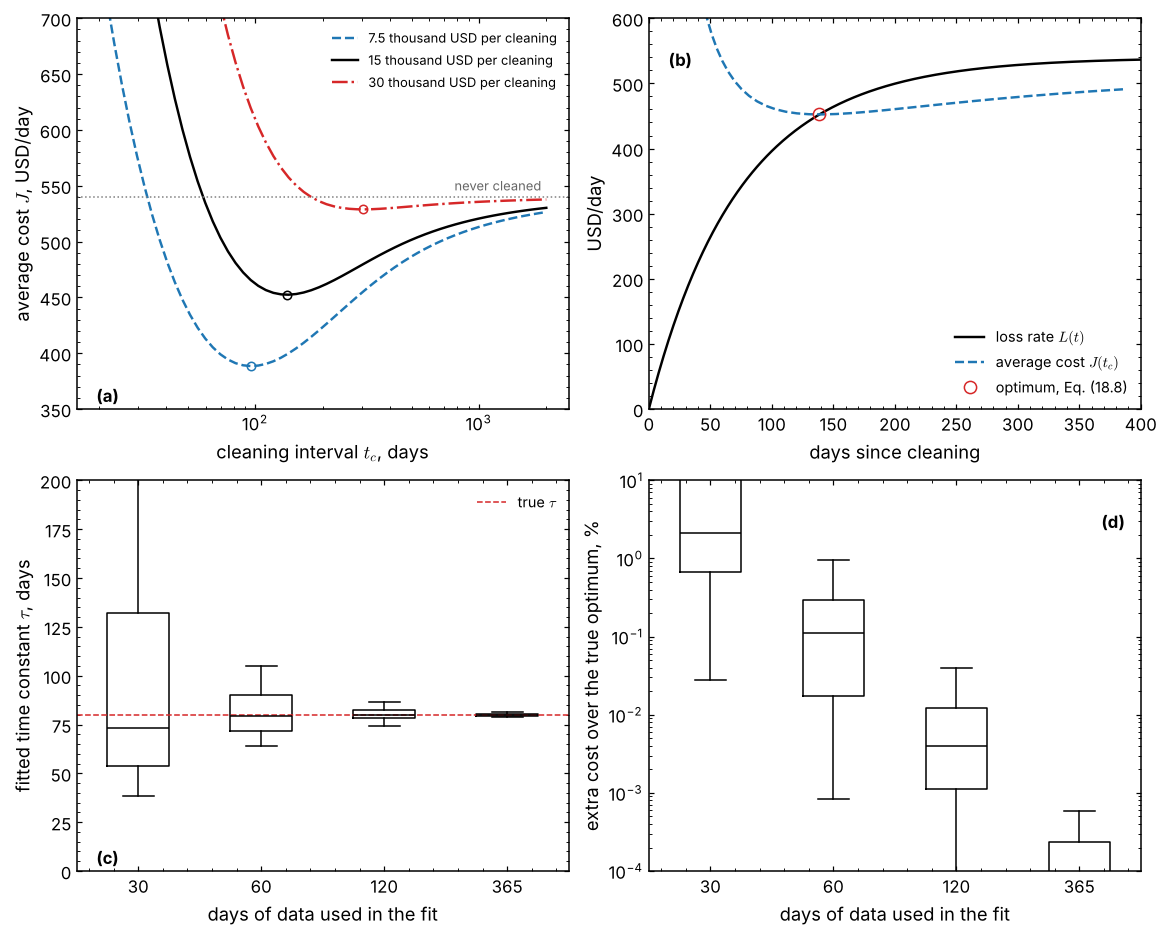

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
tc_grid = np.geomspace(20, 2000, 60)
for (C, (tc, J)), style in zip(costs.items(), ("C0--", "k-", "C3-.")):
    ax1.semilogx(tc_grid, ex.cleaning_cycle_cost(tc_grid, L_true, C, c_W * Q0, T_DOWN), style,
                 label=f"{C / 1e3:g} thousand USD per cleaning")
    if tc < 1900:
        ax1.plot(tc, J, "o", color=style[:2] if style[0] == "C" else "k", mfc="none")
ax1.axhline(L_inf, color="0.5", ls=":", lw=1.0)
ax1.text(1900, L_inf + 6, "never cleaned", fontsize=8.5, color="0.4", ha="right")
ax1.set_xlabel(r"cleaning interval $t_c$, days")
ax1.set_ylabel(r"average cost $J$, USD/day")
ax1.set_ylim(350, 700)
ax1.legend(loc="upper right", fontsize=8.5)
panel_label(ax1, "(a)", x=0.04, y=0.06)

t_fine = np.linspace(0, 400, 401)
ax2.plot(t_fine, L_true(t_fine), "k-", label=r"loss rate $L(t)$")
ax2.plot(tc_grid[tc_grid < 400], ex.cleaning_cycle_cost(tc_grid[tc_grid < 400], L_true, C_CLEAN, c_W * Q0, T_DOWN), "C0--",
         label=r"average cost $J(t_c)$")
ax2.plot(t_opt, J_opt, "C3o", mfc="none", ms=8, label="optimum, Eq. (18.8)")
ax2.set_xlabel("days since cleaning")
ax2.set_ylabel("USD/day")
ax2.set_xlim(0, 400)
ax2.set_ylim(0, 600)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)", x=0.04, y=0.92)

pos = np.arange(len(spans))
ax3.boxplot([mc[n][:, 1] for n in spans], positions=pos, widths=0.5, whis=(5, 95), showfliers=False, medianprops={"color": "k"})
ax3.axhline(TAU_TRUE, color="C3", ls="--", lw=1.0, label=r"true $\tau$")
ax3.set_xticks(pos)
ax3.set_xticklabels([str(n) for n in spans])
ax3.set_xlabel("days of data used in the fit")
ax3.set_ylabel(r"fitted time constant $\tau$, days")
ax3.set_ylim(0, 200)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

ax4.boxplot([100 * mc[n][:, 4] for n in spans], positions=pos, widths=0.5, whis=(5, 95), showfliers=False, medianprops={"color": "k"})
ax4.set_xticks(pos)
ax4.set_xticklabels([str(n) for n in spans])
ax4.set_xlabel("days of data used in the fit")
ax4.set_ylabel("extra cost over the true optimum, %")
ax4.set_yscale("log")
ax4.set_ylim(1e-4, 10)
panel_label(ax4, "(d)", x=0.92, y=0.92)
plt.show()

For the synthetic exchanger the best interval is 139 days, at an average cost of 452 USD a
day, against 540 USD a day if it is never cleaned: cleaning saves 32 thousand USD a year.
The optimum is flat. Cleaning 30 % sooner or later costs 2.6 % or 1.0 % more, while cleaning
once a year costs 8 % more and every 60 days 18 % more. Halving the cost of a cleaning
shortens the best interval to 96 days; doubling it lengthens it to 303 days; above about
66 thousand USD a cleaning never pays. The fits from 200 synthetic years show how much
data the decision needs. With 30 days the interval scatters from 89 days to "never", and
the interval chosen costs 2 % more than the best in the median year (17 % more in the worst
5 % of years). With 60
days the interval falls between 120 and 180 days and the extra cost is under 1 % in 95 %
of years; with 120 days it is negligible.

**Figure 18.2.** The cleaning decision. (a) Average cost per day against the cleaning
interval for three cleaning costs; circles mark the optima. (b) The optimum as the point
where the loss rate meets the average cost, Eq. (18.8). (c) Time constants fitted to the
first 30–365 days of 200 synthetic years (boxes: quartiles; whiskers: 5–95 %). (d) Extra
cost of cleaning at the interval chosen from each fit, relative to the true optimum.

## 18.5 Checks

The steps above can each be checked against the synthetic truth.

*The inversion.* Readings without noise must return the true $R_f$ exactly, through the
duty, the effectiveness, the inverse of Eq. (11.8) and Eq. (18.4).

*The propagation of errors.* The scatter of the daily $R_f$ about the truth in the 200
synthetic years should match Eq. (18.5), and the standard errors of the fit should match the
scatter of the fitted parameters between years: a 95 % interval should contain the truth in
about 95 % of the years.

*The optimisation.* The golden-section optimum of Eq. (18.7) is compared with SciPy's
bounded scalar minimiser and the fit with SciPy's `curve_fit`, and the optimum is checked
against the condition (18.8).

In [9]:
from scipy.optimize import curve_fit, minimize_scalar

exact = {k: true[k] for k in ("m_h", "m_c", "T_hi", "T_ho", "T_ci", "T_co")}
err_inv = fouling_from_readings(exact)["R_f"] - true["R_f"]
print(f"inversion without noise: largest error in R_f {np.max(np.abs(err_inv)):.1e} m2K/W")

rng_s = np.random.default_rng(11)
scat = []
for k in range(200):
    tr, m = plant_record(rng_s)
    scat.append(fouling_from_readings(m)["R_f"] - tr["R_f"])
scat = np.array(scat)
sd_day = scat.std(axis=0)
print(f"daily scatter of R_f: day 0 {sd_day[:10].mean():.2e}, day 300+ {sd_day[300:].mean():.2e};"
      f" Eq. (18.5): {sig0:.2e} clean, {sig1:.2e} fouled (nominal operation)")

v = mc[365]
z_tau = (v[:, 1] - TAU_TRUE) / v[:, 2]
cover = np.mean(np.abs(z_tau) < 1.96)
print(f"365-day fits: tau mean {v[:, 1].mean():.2f} (truth {TAU_TRUE}), scatter {v[:, 1].std():.2f} d,"
      f" mean standard error {v[:, 2].mean():.2f} d; 95 % intervals contain the truth in {100 * cover:.0f} % of years")
for n in (30, 60):
    zn = (mc[n][:, 1] - TAU_TRUE) / mc[n][:, 2]
    print(f"{n}-day fits: 95 % intervals contain the truth in {100 * np.mean(np.abs(zn) < 1.96):.0f} % of years")

p, c = curve_fit(lambda t, a, b: a * (1 - np.exp(-t / b)), days, est["R_f"], p0=[1e-3, 50.0])
print(f"curve_fit: R_inf {p[0]:.6e} (ours {fit['R_inf']:.6e}), tau {p[1]:.5f} (ours {fit['tau']:.5f});"
      f" standard errors {np.sqrt(c[1, 1]):.4f} vs {math.sqrt(fit['cov'][1, 1]):.4f} d")
res = minimize_scalar(lambda tc: ex.cleaning_cycle_cost(tc, L_true, C_CLEAN, c_W * Q0, T_DOWN), bounds=(10, 2000),
                      method="bounded", options={"xatol": 1e-6})
print(f"optimum: golden section {t_opt:.4f} d, SciPy {res.x:.4f} d; Eq. (18.8) residual {(L_true(np.array([t_opt]))[0] - J_opt) / J_opt:.1e}")
n_grid = (100, 200, 400, 800, 1600)
Jn = [ex.cleaning_cycle_cost(t_opt, L_true, C_CLEAN, c_W * Q0, T_DOWN, n=n) for n in n_grid]
print("cost integral, trapezoidal rule: " + ", ".join(f"n = {n}: {abs(J - Jn[-1]):.1e}" for n, J in zip(n_grid[:-1], Jn[:-1])))

inversion without noise: largest error in R_f 6.5e-18 m2K/W
daily scatter of R_f: day 0 2.97e-05, day 300+ 3.88e-05; Eq. (18.5): 2.93e-05 clean, 3.87e-05 fouled (nominal operation)
365-day fits: tau mean 79.93 (truth 80.0), scatter 0.83 d, mean standard error 0.90 d; 95 % intervals contain the truth in 96 % of years
30-day fits: 95 % intervals contain the truth in 90 % of years
60-day fits: 95 % intervals contain the truth in 96 % of years
curve_fit: R_inf 1.206127e-03 (ours 1.206127e-03), tau 81.11850 (ours 81.11851); standard errors 0.8663 vs 0.8663 d
optimum: golden section 138.7168 d, SciPy 138.7168 d; Eq. (18.8) residual 2.3e-06
cost integral, trapezoidal rule: n = 100: 7.1e-03, n = 200: 1.8e-03, n = 400: 4.2e-04, n = 800: 8.4e-05


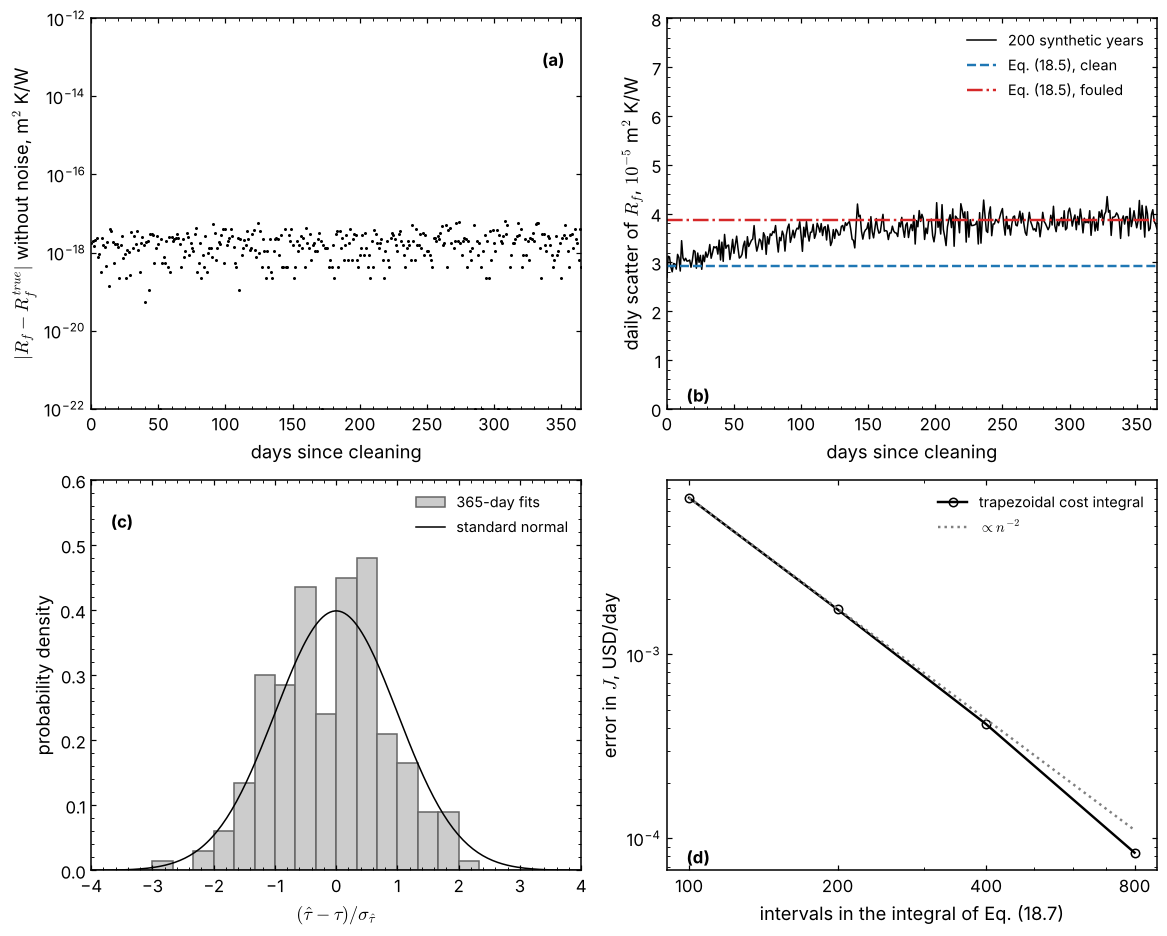

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
ax1.semilogy(days, np.abs(err_inv) + 1e-22, "k.", ms=2)
ax1.set_xlabel("days since cleaning")
ax1.set_ylabel(r"$|R_f - R_f^{true}|$ without noise, m$^2$ K/W")
ax1.set_xlim(0, 365)
ax1.set_ylim(1e-22, 1e-12)
panel_label(ax1, "(a)", x=0.92, y=0.92)

ax2.plot(days, 1e5 * sd_day, "k-", lw=1.0, label="200 synthetic years")
ax2.plot([0, 365], [1e5 * sig0, 1e5 * sig0], "C0--", label="Eq. (18.5), clean")
ax2.plot([0, 365], [1e5 * sig1, 1e5 * sig1], "C3-.", label="Eq. (18.5), fouled")
ax2.set_xlabel("days since cleaning")
ax2.set_ylabel(r"daily scatter of $R_f$, $10^{-5}$ m$^2$ K/W")
ax2.set_xlim(0, 365)
ax2.set_ylim(0, 8)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

zz = np.linspace(-4, 4, 200)
ax3.hist(z_tau, bins=np.linspace(-4, 4, 25), density=True, color="0.8", edgecolor="0.4", label="365-day fits")
ax3.plot(zz, np.exp(-zz**2 / 2) / math.sqrt(2 * math.pi), "k-", lw=1.0, label="standard normal")
ax3.set_xlabel(r"$(\hat\tau - \tau)/\sigma_{\hat\tau}$")
ax3.set_ylabel("probability density")
ax3.set_xlim(-4, 4)
ax3.set_ylim(0, 0.6)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.92)

ax4.loglog(n_grid[:-1], [abs(J - Jn[-1]) for J in Jn[:-1]], "ko-", mfc="none", label="trapezoidal cost integral")
ax4.loglog(n_grid[:-1], abs(Jn[0] - Jn[-1]) * (n_grid[0] / np.array(n_grid[:-1])) ** 2, ":", color="0.5", label=r"$\propto n^{-2}$")
ax4.set_xticks(n_grid[:-1])
ax4.xaxis.set_major_formatter(plt.ScalarFormatter())
ax4.xaxis.set_minor_formatter(plt.NullFormatter())
ax4.set_xlabel("intervals in the integral of Eq. (18.7)")
ax4.set_ylabel("error in $J$, USD/day")
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 18.3.** Checks. (a) Error of the fouling resistance recovered from noise-free
readings. (b) Daily scatter of the recovered resistance in 200 synthetic years, against the
propagation of errors (18.5). (c) Fitted time constants of the 365-day fits, in units of
their own standard errors, against the standard normal distribution. (d) Convergence of
the cost integral in Eq. (18.7).

Without noise the inversion returns the true resistance to $10^{-17}$ m² K/W. With noise,
the daily scatter in the synthetic years is $2.97\times10^{-5}$ just after cleaning and
$3.88\times10^{-5}$ late in the year, as Eq. (18.5) gives ($2.93$ and $3.87$); the small
excess comes from the day-to-day changes of operation, which Eq. (18.5) evaluated at the
nominal point leaves out. The standard errors of the 365-day and 60-day fits are honest:
their 95 % intervals contain the true $\tau$ in 96 % of the years. After 30 days they do so
in only 90 %, because the linearised error is a poor guide when $\tau$ is barely
determined. The fit agrees with SciPy's `curve_fit` to seven digits, the optimum with
SciPy's bounded minimiser to $10^{-4}$ days, and the optimum satisfies Eq. (18.8) to
$2\times10^{-6}$. The trapezoidal cost integral converges at second order.

## 18.6 What to trust

* *The fouling law* is an assumption. Crude oil fouling often shows an induction period, a
  linear rate, or a rate that depends on wall temperature and velocity; fit more than one
  law, compare the residuals, and prefer the one whose parameters make physical sense.
  Exercise 1 asks what happens when the law is wrong.
* *The clean coefficient* sets the zero of $R_f$; an error in $U_{clean}$ shifts every
  $R_f$ by the same amount and is invisible to the fit.
* *Instruments drift*, and a slow drift of a thermocouple looks exactly like fouling. A
  growing heat-balance imbalance (18.2) is the warning.
* *Costs* change: fuel prices, production lost during cleaning, and the hydraulic cost of
  fouling (pressure drop) all move the optimum. The flat bottom of $J(t_c)$ makes the
  decision robust to most of them.

## Summary

* Daily readings of flows and temperatures give UA through the duty and the inverse
  effectiveness relation, Eqs. (18.2)–(18.4); unlike the duty, UA isolates the fouling from
  the changes of operation.
* The noise of the readings passes into the fouling resistance by Eq. (18.5); here each day
  is uncertain by 2–3 % of the asymptote, but a year determines the Kern–Seaton law (18.1)
  to about 1 %.
* The cleaning interval minimises the average cost (18.7) where the loss rate meets the
  average cost, Eq. (18.8); for the synthetic exchanger and the assumed costs it is 139
  days, and the cost curve is so flat that fits from two months of data already set it
  within 1 % of the best cost in 95 % of the years; one month of data is not enough.
* With asymptotic fouling an expensive cleaning may never pay: the optimum moves to
  infinity once the cleaning costs more than the heat lost while the deposit grows.

## Exercises

Sample solutions are in [`solutions/part4_mass_transfer/18_solutions.ipynb`](../../solutions/part4_mass_transfer/18_solutions.ipynb).

1. **The wrong law.** Generate a synthetic year in which the fouling grows linearly,
   $R_f = 4\times10^{-6}t$ m² K/W with $t$ in days, and fit both the linear and the
   asymptotic law to the first 120 days. Which fits better by the residual scatter, and
   what cleaning interval does each recommend? Then reverse the roles: fit a straight line
   to the first 120 days of the asymptotic year of Section 18.1. What does following it cost?
2. **A drifting thermocouple.** In the synthetic year of Section 18.1, let the outlet
   thermocouple of the crude drift upwards by 0.01 K per day. How does this change the
   fitted $R_\infty$ and $\tau$, and the recommended interval? How could the heat-balance
   imbalance reveal the drift?
3. **Which instrument matters?** Using Eq. (18.5), find which of the six readings
   contributes most to the scatter of $R_f$. How does the scatter change if the
   temperatures are measured to 0.1 K instead of 0.3 K, and if the flows are measured to
   0.5 % instead of 1 %? Why does the effectiveness of the exchanger matter for how well
   fouling can be measured?
4. **Cleaning in the cold season.** Suppose the furnace is short of capacity in winter but
   not in summer, so that lost heat costs twice as much from November to March. Cleaning is
   done once a year; on which day of the year should it be done, starting from the
   synthetic law and costs of Section 18.4? (Take the year as 365 days and the fouling as
   restarting at each cleaning.)

## Suggested references

* D. Q. Kern and R. E. Seaton, "A theoretical analysis of thermal surface fouling", *Brit.
  Chem. Eng.* **4**, 258 (1959).
* J. Taborek, T. Aoki, R. B. Ritter, J. W. Palen and J. G. Knudsen, "Fouling: the major
  unresolved problem in heat transfer", *Chem. Eng. Prog.* **68**(2), 59 (1972).
* H. Müller-Steinhagen, "Heat transfer fouling: 50 years after the Kern and Seaton model",
  *Heat Transfer Eng.* **32**, 1 (2011).

---

**Previous:** [17. Simultaneous heat and mass transfer](17_simultaneous_heat_mass.ipynb) &nbsp;·&nbsp; [Back to the contents](../../docs/intro.md)